#### 비선형 이진분류(동심원 데이터)

In [1]:
import torch
import matplotlib.pyplot as plt

#### Step 1. 데이터 생성

In [2]:
#선형(Linear 함수)으로는 분류가 불가능한 데이터

N = 100

# 0.3 주변의 값(50)
radius1 = 0.3 + 0.05*torch.randn(int(N/2), 1)   # 평균이 0.3, 표준편차가 0.05인 랜덤한 값 50개

# 1 주변의 값(50)
radius2 = 1 + 0.01*torch.randn(int(N/2),1)      # 평균이 1, 표준편차가 0.01인 랜덤한 값 50개

# 각도 만들기
theta1 = 2 * torch.pi * torch.rand(int(N/2),1) - torch.pi  # -180 ~ +180도(2pi) 사이의 50개의 각도 생성
theta2 = 2 * torch.pi * torch.rand(int(N/2),1) - torch.pi

# 극좌표 (r, theta)를 직교좌표 (x, y)로 변환
# x = r * cos(theta)
# y = r * sin(theta)
#
# r: 원점에서 점까지의 거리
# theta: 양의 x축에서 반시계 방향으로 잰 각도
# Python의 삼각함수에는 theta를 라디안 단위로 입력

# (50, 2)의 데이터
class1_data = torch.hstack([radius1 * torch.cos(theta1), radius1 * torch.sin(theta1)])
class2_data = torch.hstack([radius2 * torch.cos(theta2), radius2 * torch.sin(theta2)])

# (50, 1)의 데이터 레이블 생성
# 예측값의 결과는 1에 가깝게 또는 0에 가깝게로 예측될 수 있도록 ones, zeros로 생성
class1_label = torch.ones(int(N/2),1)
class2_label = torch.zeros(int(N/2),1)

# 입력값 X, Target Y 생성
X = torch.vstack([class1_data, class2_data])
Y = torch.vstack([class1_label, class2_label])

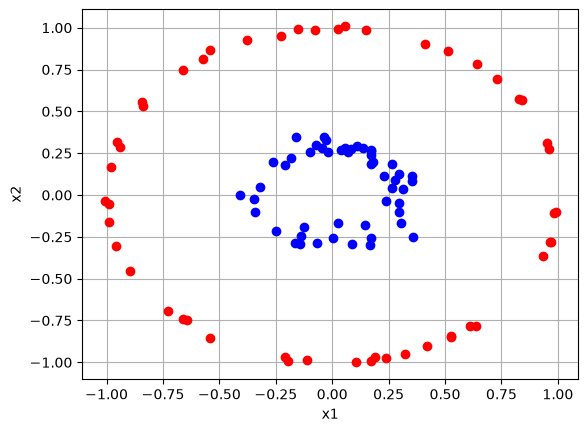

In [3]:
plt.plot(class1_data[:,0], class1_data[:,1], 'bo')
plt.plot(class2_data[:,0], class2_data[:,1], 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid()
plt.show()

#### STEP 2. 모델 만들기

In [ ]:
from torch import nn
class MLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.linear = nn.Sequential(nn.Linear(2, 100),
                                    nn.Sigmoid(),
                                    nn.Linear(100,1),
                                    nn.Sigmoid()
                                    )

        # # 은닉층 개수 추가
        # self.linear = nn.Sequential(nn.Linear(2, 100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100,100),
        #                             nn.Sigmoid(),
        #                             nn.Linear(100,100),
        #                             nn.Sigmoid(),
        #                             *[nn.Sequential(nn.Linear(100,100),nn.Sigmoid()) for _ in range(10)],
        #                             # NOTE *[ ] : 대괄호를 unpacking해서 집어넣기
        #                             nn.Linear(100,1),
        #                             nn.Sigmoid()                                    
        #                             )

        # # ReLU 함수 사용
        # self.linear = nn.Sequential(nn.Linear(2, 100),
        #                             nn.ReLU(),
        #                             nn.Linear(100,1),
        #                             nn.Sigmoid()
        #                             )
    def forward(self, x):
        x = self.linear(x)
        return x

은닉층의 개수를 늘리고 이에 맞춰서 학습률과 주기를 늘렸을때, 과적합이 발생함
- 예측확률 평면이 데이터 사이 공간을 비집고 튀어나가는 형태 

Sigmoid 활성함수 대신 ReLU 활성함수 사용시 과적합이 발생함
- loss 값이 15번째 주기부터 0에 수렴함

In [5]:
model = MLP()

#### Step 3. 모델 학습시키기

In [ ]:
from torch import optim
LR = 1e-1
# LR = 1e-2
EPOCH = 100
# EPOCH = 500

# 비선형은 Adam이 더 잘 맞음
optimizer = optim.Adam(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history= []

model.train()   # train mode
for ep in range(EPOCH):
    # 예측값
    y_hat = model(X)

    # Loss
    loss = criterion(y_hat, Y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 학습곡선을 위한 Loss 기록
    loss_history += [loss.item()]

    # print
    print(f'EPOCH: {ep+1}, train loss: {loss.item():.4f}')
    print('-'*30)

EPOCH: 1, train loss: 0.697901
------------------------------
EPOCH: 2, train loss: 0.677828
------------------------------
EPOCH: 3, train loss: 0.626768
------------------------------
EPOCH: 4, train loss: 0.515079
------------------------------
EPOCH: 5, train loss: 0.326694
------------------------------
EPOCH: 6, train loss: 0.246012
------------------------------
EPOCH: 7, train loss: 0.196712
------------------------------
EPOCH: 8, train loss: 0.122126
------------------------------
EPOCH: 9, train loss: 0.083567
------------------------------
EPOCH: 10, train loss: 0.069240
------------------------------
EPOCH: 11, train loss: 0.051817
------------------------------
EPOCH: 12, train loss: 0.032565
------------------------------
EPOCH: 13, train loss: 0.019039
------------------------------
EPOCH: 14, train loss: 0.011773
------------------------------
EPOCH: 15, train loss: 0.008090
------------------------------
EPOCH: 16, train loss: 0.006029
------------------------------
E

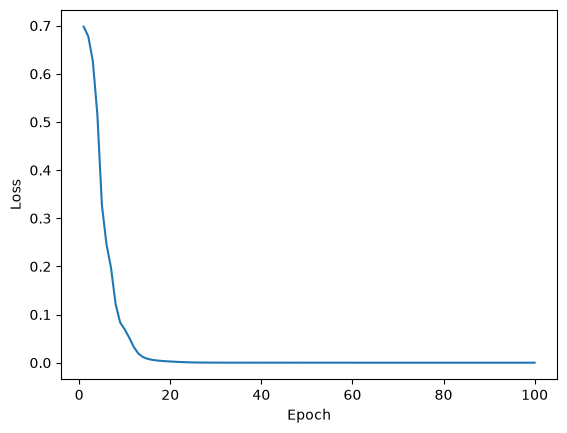

In [7]:
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

#### Step 4. 모델 테스트

c:\Users\mega\KYJ\PyTorch\.venv\Lib\site-packages\torch\functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4209.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


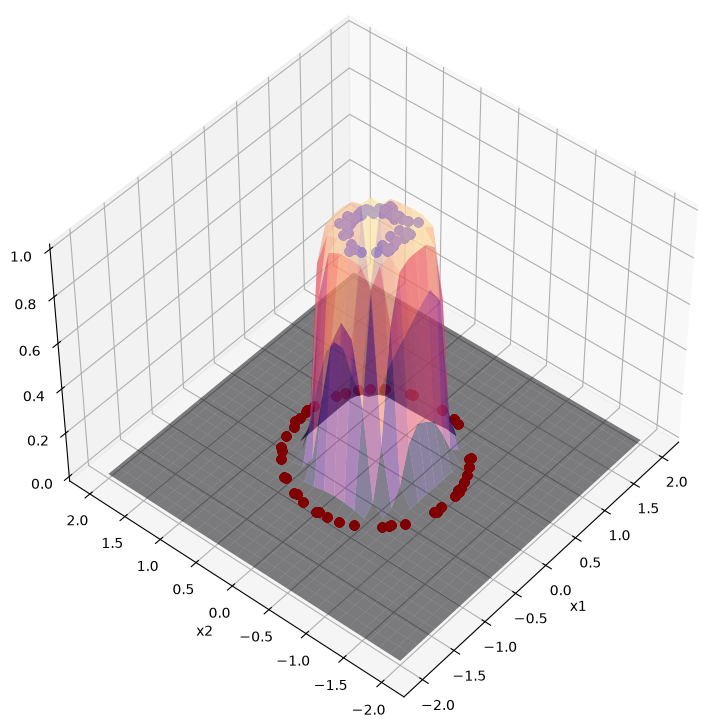

In [8]:
x1_test = torch.linspace(-2, 2, 30)
x2_test = torch.linspace(-2, 2, 30)

X1_test, X2_test = torch.meshgrid(x1_test, x2_test)

X_test = torch.cat([X1_test.unsqueeze(dim=2), X2_test.unsqueeze(dim=2)], dim=2)

model.eval()
with torch.no_grad():
    y_hat = model(X_test)

Y_hat = y_hat.squeeze()

plt.figure(figsize= (10,9))
ax = plt.axes(projection= '3d')
ax.view_init(elev = 45, azim = -140)

ax.plot_surface(X1_test, X2_test, Y_hat.numpy(), cmap='magma', alpha=0.5)
plt.plot(class1_data[:,0], class1_data[:,1], class1_label, 'bo')
plt.plot(class2_data[:,0], class2_data[:,1], class2_label, 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

#### SGD 로 바꾸면?

In [9]:
from torch import optim
LR = 1e-1
EPOCH = 100

optimizer = optim.Adam(model.parameters(), lr = LR)
criterion = nn.BCELoss()

loss_history= []

model.train()   # train mode
for ep in range(EPOCH):
    # 예측값
    y_hat = model(X)

    # Loss
    loss = criterion(y_hat, Y)

    # update
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # 학습곡선을 위한 Loss 기록
    loss_history += [loss.item()]

    # print
    print(f'EPOCH: {ep+1}, train loss: {loss.item():.4f}')
    print('-'*30)

EPOCH: 1, train loss: 0.0000
------------------------------
EPOCH: 2, train loss: 0.0109
------------------------------
EPOCH: 3, train loss: 0.0000
------------------------------
EPOCH: 4, train loss: 0.0006
------------------------------
EPOCH: 5, train loss: 0.0106
------------------------------
EPOCH: 6, train loss: 0.0086
------------------------------
EPOCH: 7, train loss: 0.0021
------------------------------
EPOCH: 8, train loss: 0.0008
------------------------------
EPOCH: 9, train loss: 0.0006
------------------------------
EPOCH: 10, train loss: 0.0002
------------------------------
EPOCH: 11, train loss: 0.0001
------------------------------
EPOCH: 12, train loss: 0.0002
------------------------------
EPOCH: 13, train loss: 0.0005
------------------------------
EPOCH: 14, train loss: 0.0007
------------------------------
EPOCH: 15, train loss: 0.0005
------------------------------
EPOCH: 16, train loss: 0.0003
------------------------------
EPOCH: 17, train loss: 0.0003
---

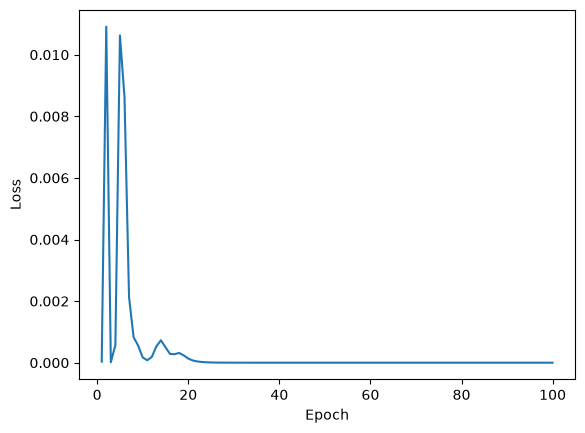

In [10]:
plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

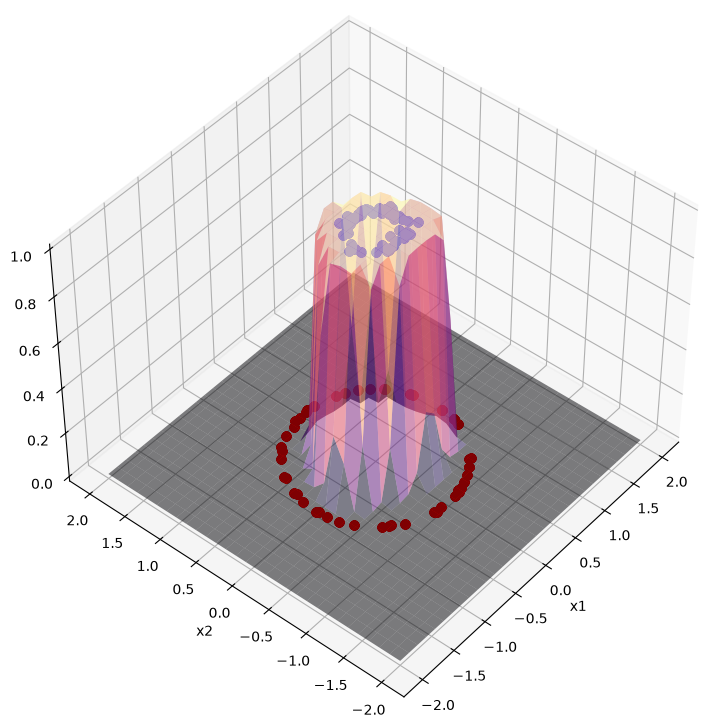

In [11]:
x1_test = torch.linspace(-2, 2, 30)
x2_test = torch.linspace(-2, 2, 30)

X1_test, X2_test = torch.meshgrid(x1_test, x2_test)

X_test = torch.cat([X1_test.unsqueeze(dim=2), X2_test.unsqueeze(dim=2)], dim=2)

model.eval()
with torch.no_grad():
    y_hat = model(X_test)

Y_hat = y_hat.squeeze()

plt.figure(figsize= (10,9))
ax = plt.axes(projection= '3d')
ax.view_init(elev = 45, azim = -140)

ax.plot_surface(X1_test, X2_test, Y_hat.numpy(), cmap='magma', alpha=0.5)
plt.plot(class1_data[:,0], class1_data[:,1], class1_label, 'bo')
plt.plot(class2_data[:,0], class2_data[:,1], class2_label, 'ro')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()